In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

sns.set_theme(style="whitegrid")

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as outer_zip:
    print("Files in the downloaded ZIP:")
    print(outer_zip.namelist())

    # The UCI download contains another ZIP file.
    inner_zip_name = next(
        name for name in outer_zip.namelist()
        if name.endswith("bank.zip")
    )
    inner_zip_bytes = outer_zip.read(inner_zip_name)

with zipfile.ZipFile(io.BytesIO(inner_zip_bytes)) as inner_zip:
    csv_file = next(
        name for name in inner_zip.namelist()
        if name.endswith("bank-full.csv")
    )

    with inner_zip.open(csv_file) as f:
        df = pd.read_csv(f, sep=";")

print("\nDataset shape:", df.shape)
df.info()
display(df.head())
display(df.describe(include="all").T)


Files in the downloaded ZIP:
['bank.zip', 'bank-additional.zip']

Dataset shape: (45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target proportions:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


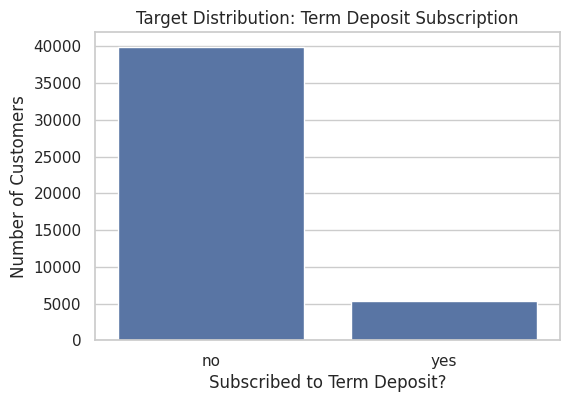

In [3]:

# Show how many customers subscribed to a term deposit

print("Target distribution:")
print(df["y"].value_counts())

print("\nTarget proportions:")
print(df["y"].value_counts(normalize=True) * 100)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y")
plt.title("Target Distribution: Term Deposit Subscription")
plt.xlabel("Subscribed to Term Deposit?")
plt.ylabel("Number of Customers")
plt.show()


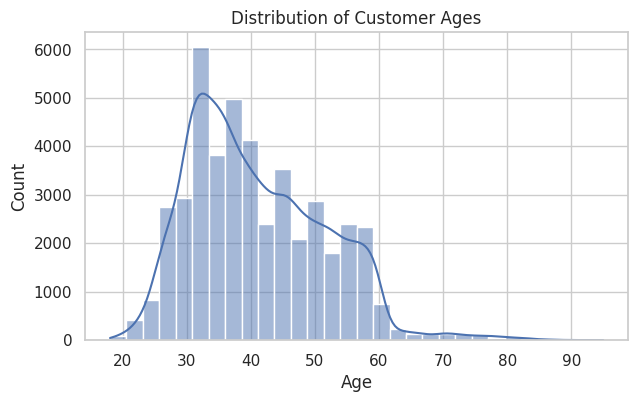

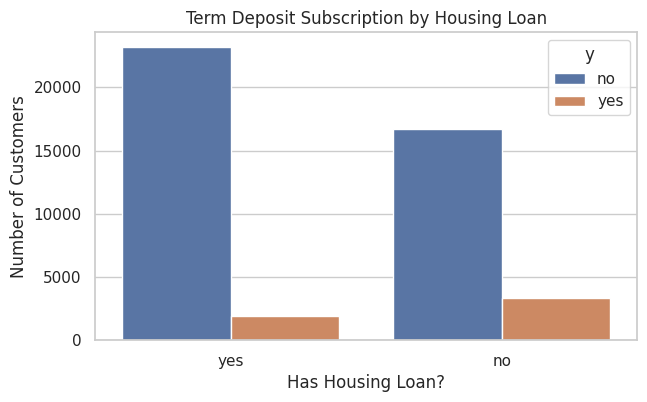

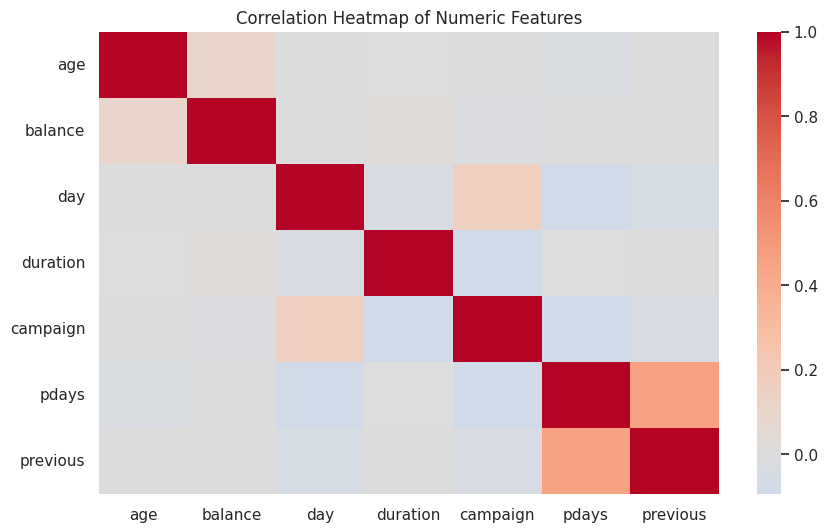

In [4]:

# Chart 1: Distribution of customer ages
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

# Chart 2: Subscription by housing loan status
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="housing", hue="y")
plt.title("Term Deposit Subscription by Housing Loan")
plt.xlabel("Has Housing Loan?")
plt.ylabel("Number of Customers")
plt.show()

# Chart 3: Correlation heatmap
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


### EDA Observations

The target distribution shows the number of customers who subscribed and those who did not. The age histogram helps us understand the age range of customers. The housing loan chart compares subscription outcomes for customers with and without housing loans. The correlation heatmap shows relationships between numerical features.

Duplicate rows: 0
Shape after removing duplicates: (45211, 17)

Missing values per column:


,Missing Values
poutcome,36959
contact,13020
education,1857
job,288
age,0
default,0
balance,0
housing,0
marital,0
loan,0


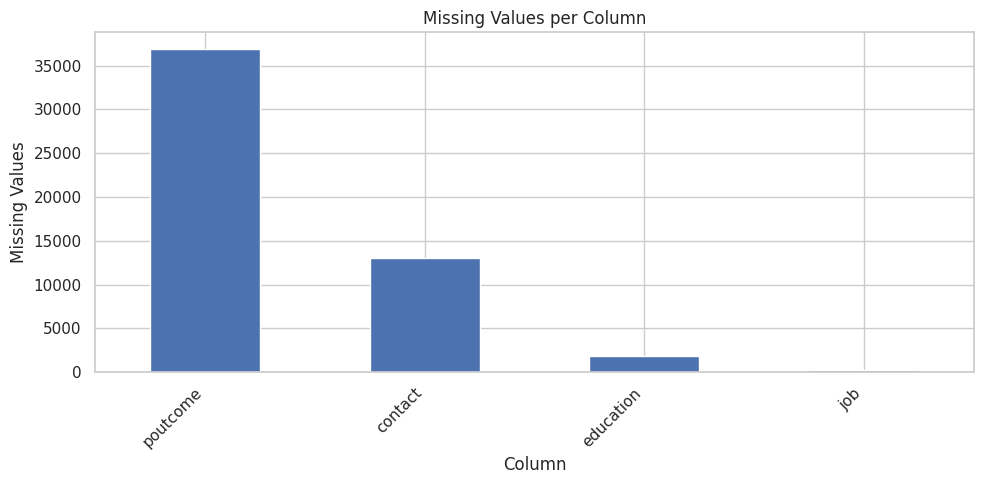

In [5]:

# Check and remove duplicate rows
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)

# Convert 'unknown' values into missing values
df = df.replace("unknown", np.nan)

# Count missing values in each column
missing_counts = df.isna().sum().sort_values(ascending=False)

print("\nMissing values per column:")
display(missing_counts.to_frame(name="Missing Values"))

# Plot missing values
missing_counts = missing_counts[missing_counts > 0]

plt.figure(figsize=(10, 5))
missing_counts.plot(kind="bar")
plt.title("Missing Values per Column")
plt.xlabel("Column")
plt.ylabel("Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Cleaning Decisions

- **Duplicates:** No duplicate rows were found, so no rows were removed.
- **poutcome:** The column has many missing values because the outcome of a previous campaign is often unavailable. We will fill missing values using the most frequent value learned from the training data.
- **contact:** Missing contact methods will be filled with the most frequent category.
- **education:** Missing education information will be filled with the most frequent category.
- **job:** Missing job information will be filled with the most frequent category.
- **Other columns:** No missing values were found in these columns.
- **ID/name columns:** There are no personal name or ID columns to remove.

Missing values will be handled during preprocessing after the train/test split to prevent data leakage.

In [6]:

# Feature 1: Group customers by age
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"],
    include_lowest=True
)

# Feature 2: Total contacts across current and previous campaigns
df["total_contacts"] = df["campaign"] + df["previous"]

# Display the new features
display(
    df[[
        "age",
        "age_group",
        "campaign",
        "previous",
        "total_contacts"
    ]].head(10)
)

print("New dataset shape:", df.shape)


,age,age_group,campaign,previous,total_contacts
0,58,56+,1,0,1
1,44,36-45,1,0,1
2,33,26-35,1,0,1
3,47,46-55,1,0,1
4,33,26-35,1,0,1
5,35,26-35,1,0,1
6,28,26-35,1,0,1
7,42,36-45,1,0,1
8,58,56+,1,0,1
9,43,36-45,1,0,1


New dataset shape: (45211, 19)


### Feature Engineering Decisions

1. **age_group:** Groups customers into age ranges, which may help the model identify differences in subscription patterns between age groups.
2. **total_contacts:** Combines the number of contacts from current and previous campaigns. It may help the model understand how frequently a customer has been contacted.

These features provide additional information that may be useful for predicting term deposit subscriptions.

In [7]:

# Select input features and target
X = df.drop(columns=["y"]).copy()
y = df["y"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())


X shape: (45211, 18)
y shape: (45211,)

Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64


In [8]:

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train_raw.shape)
print("Testing features:", X_test_raw.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))


Training features: (36168, 18)
Testing features: (9043, 18)
Training target: (36168,)
Testing target: (9043,)

Training class proportions:
y
no     0.883018
yes    0.116982
Name: proportion, dtype: float64

Testing class proportions:
y
no     0.883003
yes    0.116997
Name: proportion, dtype: float64


In [9]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Separate numeric and categorical columns
numeric_columns = X_train_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric columns:", numeric_columns)
print("\nCategorical columns:", categorical_columns)

# Pipeline for numeric columns
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical columns
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# Fit on training data and transform training data
X_train_processed = preprocessor.fit_transform(X_train_raw)

# Transform test data without fitting again
X_test_processed = preprocessor.transform(X_test_raw)

# Convert sparse matrices to NumPy arrays
X_train = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

print("\nPreprocessing completed successfully!")


Numeric columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'total_contacts']

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'age_group']

Preprocessing completed successfully!


In [10]:

# Check final shapes
print("Final output shapes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check for missing values
print("\nMissing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test:", np.isnan(X_test).sum())

# Verify row counts match
assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]

# Verify no missing values remain
assert not np.isnan(X_train).any()
assert not np.isnan(X_test).any()

print("\nAll final checks passed!")
print("Preprocessor fitted on training data only.")
print("Test data transformed without refitting.")


Final output shapes:
X_train: (36168, 53)
X_test: (9043, 53)
y_train: (36168,)
y_test: (9043,)

Missing values in X_train: 0
Missing values in X_test: 0

All final checks passed!
Preprocessor fitted on training data only.
Test data transformed without refitting.


## Conclusion

In this project, I prepared the Bank Marketing dataset for machine learning. I explored the data using charts and summary statistics, checked duplicate rows, handled unknown values as missing data, and created two new features: `age_group` and `total_contacts`.

I divided the data into 80% training and 20% testing sets using stratification. I used median imputation and StandardScaler for numerical features, and most-frequent imputation and OneHotEncoder for categorical features.

To avoid data leakage, I fitted the preprocessing pipeline only on the training data and transformed the test data separately.

The final outputs are `X_train` (36,168 × 53), `X_test` (9,043 × 53), `y_train` (36,168), and `y_test` (9,043). Both processed feature sets contain zero missing values.